In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("/content/Zomato Dataset.csv")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  object 
 9   Time_Orderd                  43853 non-null  object 
 10  Time_Order_picked            45584 non-null  object 
 11  Weather_conditions           44968 non-null  object 
 12  Road_traffic_density         44983 non-null  object 
 13  Vehicle_conditio

In [6]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [7]:
df.shape

(45584, 20)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['City'].unique()

array(['Metropolitian', 'Urban', 'Semi-Urban', nan], dtype=object)

In [10]:
df.isnull().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,1854
Delivery_person_Ratings,1908
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,1731


In [11]:
na = df.isna().sum()
na[na > 0]

,0
Delivery_person_Age,1854
Delivery_person_Ratings,1908
Time_Orderd,1731
Weather_conditions,616
Road_traffic_density,601
multiple_deliveries,993
Festival,228
City,1200


In [12]:
cols_na = na[na > 0].index.tolist()

In [13]:
for c in cols_na:
    print(c)
    print(df.groupby(df[c].isna())["Time_taken (min)"].mean().round(1))
    print()

Delivery_person_Age
Delivery_person_Age
False    26.3
True     26.5
Name: Time_taken (min), dtype: float64

Delivery_person_Ratings
Delivery_person_Ratings
False    26.3
True     26.4
Name: Time_taken (min), dtype: float64

Time_Orderd
Time_Orderd
False    26.3
True     26.3
Name: Time_taken (min), dtype: float64

Weather_conditions
Weather_conditions
False    26.3
True     26.5
Name: Time_taken (min), dtype: float64

Road_traffic_density
Road_traffic_density
False    26.3
True     26.5
Name: Time_taken (min), dtype: float64

multiple_deliveries
multiple_deliveries
False    26.4
True     22.8
Name: Time_taken (min), dtype: float64

Festival
Festival
False    26.4
True     11.2
Name: Time_taken (min), dtype: float64

City
City
False    26.4
True     22.1
Name: Time_taken (min), dtype: float64



In [14]:
df["Festival"] = df["Festival"].fillna("Unknown")

In [15]:
df["Festival"].value_counts()

,count
Festival,
No,44460
Yes,896
Unknown,228


In [16]:
for c in ["Weather_conditions", "Road_traffic_density", "City"]:
    df[c] = df[c].fillna("Unknown")

In [17]:
df[["Weather_conditions", "Road_traffic_density", "City", "Festival"]].isna().sum()

,0
Weather_conditions,0
Road_traffic_density,0
City,0
Festival,0


In [18]:
df.isna().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,1854
Delivery_person_Ratings,1908
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,1731


In [19]:
df.groupby("multiple_deliveries", dropna=False)["Time_taken (min)"].agg(["count", "mean"]).round(1)

,count,mean
multiple_deliveries,,
0.0,14094,22.9
1.0,28151,26.9
2.0,1985,40.5
3.0,361,47.8
NaN,993,22.8


In [20]:
na_md = df[df["multiple_deliveries"].isna()]
na_md["Time_taken (min)"].describe()

,Time_taken (min)
count,993.000000
mean,22.767372
std,8.714170
min,10.000000
25%,16.000000
50%,21.000000
75%,28.000000
max,54.000000


/tmp/ipykernel_1876/1179078459.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([na_md["Time_taken (min)"], df[df["multiple_deliveries"] == 0]["Time_taken (min)"]],


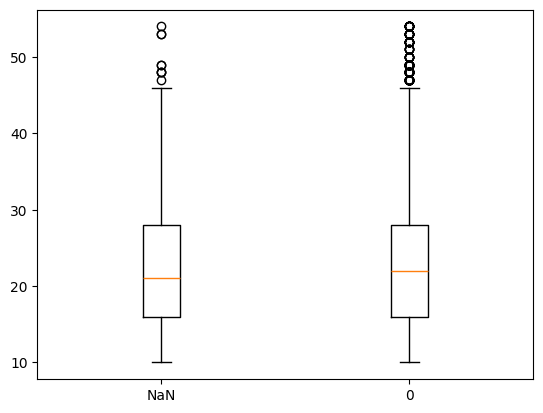

In [21]:
plt.boxplot([na_md["Time_taken (min)"], df[df["multiple_deliveries"] == 0]["Time_taken (min)"]],
            labels=["NaN", "0"])
plt.show()

In [22]:
na_md.sort_values("Time_taken (min)").head(10)
na_md.sort_values("Time_taken (min)").tail(10)

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
38924,0x45e8,INDORES03DEL02,34.0,4.6,22.751857,75.866699,22.881857,75.996699,14-03-2022,21:50,21:55,Cloudy,Jam,0,Buffet,motorcycle,NaN,No,Metropolitian,46
11930,0x2246,HYDRES03DEL02,38.0,4.3,17.422819,78.449578,17.442819,78.469578,03-04-2022,11:20,11:30,Sandstorms,High,0,Snack,motorcycle,NaN,No,Metropolitian,47
18169,0x9887,BANGRES14DEL01,38.0,4.7,12.949934,77.699386,13.019934,77.769386,16-03-2022,0.916666667,22:15,Cloudy,Jam,1,Drinks,scooter,NaN,No,Metropolitian,48
14502,0x35a3,MYSRES01DEL03,35.0,5.0,12.311072,76.654878,12.341072,76.684878,03-03-2022,20:45,20:50,Sandstorms,Jam,0,Snack,motorcycle,NaN,No,Metropolitian,48
27792,0x263f,INDORES02DEL01,30.0,4.1,22.651847,75.881991,22.761847,75.991991,04-04-2022,19:25,19:30,Cloudy,Jam,1,Buffet,motorcycle,NaN,No,Metropolitian,48
13210,0x8778,HYDRES11DEL02,32.0,4.3,17.430448,78.418213,17.560448,78.548213,02-03-2022,21:45,21:50,Cloudy,Jam,1,Meal,motorcycle,NaN,Yes,Metropolitian,49
7950,0x2411,HYDRES02DEL03,37.0,4.1,17.412330,78.449654,17.502330,78.539654,16-03-2022,19:10,19:20,Fog,Jam,2,Buffet,scooter,NaN,No,Metropolitian,49
6572,0x13ed,RANCHIRES01DEL01,36.0,4.9,23.416792,85.316842,23.486792,85.386842,10-03-2022,0.875,21:05,Cloudy,Jam,0,Meal,motorcycle,NaN,Yes,Metropolitian,53
25533,0x2300,PUNERES15DEL03,34.0,4.6,18.636215,73.751081,18.726215,73.841081,02-03-2022,20:40,20:50,Windy,Jam,0,Snack,motorcycle,NaN,Yes,Metropolitian,53
25204,0x32e6,SURRES14DEL02,34.0,4.9,21.157729,72.768726,21.287729,72.898726,29-03-2022,21:10,21:25,Cloudy,Jam,0,Meal,motorcycle,NaN,No,Metropolitian,54


In [23]:
df["md_was_missing"] = df["multiple_deliveries"].isna()
df["multiple_deliveries"] = df["multiple_deliveries"].fillna(0)

In [24]:
df["md_was_missing"].sum()

np.int64(993)

In [25]:
versi_a = df.groupby("multiple_deliveries")["Time_taken (min)"].agg(["count", "mean"]).round(1)
versi_a

,count,mean
multiple_deliveries,,
0.0,15087,22.9
1.0,28151,26.9
2.0,1985,40.5
3.0,361,47.8


In [26]:
versi_b = df[~df["md_was_missing"]].groupby("multiple_deliveries")["Time_taken (min)"].agg(["count", "mean"]).round(1)
versi_b

,count,mean
multiple_deliveries,,
0.0,14094,22.9
1.0,28151,26.9
2.0,1985,40.5
3.0,361,47.8


In [27]:
df["Delivery_person_Ratings"].value_counts(dropna=False).sort_index()

,count
Delivery_person_Ratings,
1.0,38
2.5,20
2.6,22
2.7,22
2.8,19
2.9,19
3.0,6
3.1,29
3.2,29


In [28]:
aneh = df[(df["Delivery_person_Ratings"] > 5) | (df["Delivery_person_Age"] < 18)]
aneh[["Delivery_person_ID", "Delivery_person_Age", "Delivery_person_Ratings", "Time_taken (min)"]].head(15)

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Time_taken (min)
2378,JAPRES15DEL03,15.0,1.0,15
2896,INDORES010DEL03,15.0,1.0,29
2942,SURRES17DEL03,15.0,1.0,20
3577,BANGRES05DEL01,50.0,6.0,25
4705,HYDRES17DEL01,50.0,6.0,27
5160,JAPRES08DEL01,50.0,6.0,20
5353,BANGRES19DEL01,50.0,6.0,18
5642,AGRRES13DEL02,50.0,6.0,20
5893,CHENRES15DEL03,15.0,1.0,25
6385,JAPRES06DEL02,50.0,6.0,20


In [29]:
pd.crosstab(df["Delivery_person_Age"].isna(), df["Delivery_person_Ratings"].isna())

Delivery_person_Ratings,False,True
Delivery_person_Age,,
False,43676,54
True,0,1854


In [30]:
pd.crosstab(df["Delivery_person_Age"], df["Delivery_person_Ratings"].isin([1.0, 6.0]))

Delivery_person_Ratings,False,True
Delivery_person_Age,,
15.0,0,38
20.0,2136,0
21.0,2153,0
22.0,2194,0
23.0,2086,0
24.0,2210,0
25.0,2174,0
26.0,2159,0
27.0,2150,0


In [31]:
df = df[~df["Delivery_person_Ratings"].isin([1.0, 6.0])]

In [32]:
df = df.dropna(subset=["Delivery_person_Age", "Delivery_person_Ratings", "Time_Orderd"])

In [33]:
print(len(df))
print(df["Time_taken (min)"].mean().round(2))
print(df.isna().sum().sum())

43585
26.29
0


In [34]:
def ke_menit(x):
    s = str(x).strip()
    if ":" in s:
        jam, menit = s.split(":")[:2]
        total = int(jam) * 60 + int(menit)
    else:
        total = round(float(s) * 24 * 60)
    return total % 1440

df["order_min"]  = df["Time_Orderd"].apply(ke_menit)
df["picked_min"] = df["Time_Order_picked"].apply(ke_menit)

In [35]:
df["prep_time_min"] = (df["picked_min"] - df["order_min"]) % 1440
df["order_hour"]    = df["order_min"] // 60

In [36]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%d-%m-%Y")

In [37]:
df["prep_time_min"].value_counts()

,count
prep_time_min,
5,14597
15,14517
10,14471


In [38]:
df.groupby("order_hour")["Time_taken (min)"].mean()

,Time_taken (min)
order_hour,
0,22.139860
8,19.584718
9,19.546066
10,19.483822
11,26.395074
12,26.821871
13,27.499356
14,27.538854
15,23.199770


In [39]:
df.groupby("prep_time_min")["Time_taken (min)"].mean()

,Time_taken (min)
prep_time_min,
5,26.356649
10,26.361274
15,26.156300


In [40]:
pd.crosstab(df["order_hour"], df["Road_traffic_density"])

Road_traffic_density,High,Jam,Low,Medium
order_hour,,,,
0,0,0,429,0
8,0,0,1806,0
9,0,0,1932,0
10,0,0,1978,0
11,1757,0,192,0
12,887,0,0,0
13,777,0,0,0
14,785,0,0,0
15,86,0,0,785


In [41]:
pd.crosstab(df["order_hour"], df["Road_traffic_density"], normalize="index").round(2)

Road_traffic_density,High,Jam,Low,Medium
order_hour,,,,
0,0.0,0.00,1.00,0.00
8,0.0,0.00,1.00,0.00
9,0.0,0.00,1.00,0.00
10,0.0,0.00,1.00,0.00
11,0.9,0.00,0.10,0.00
12,1.0,0.00,0.00,0.00
13,1.0,0.00,0.00,0.00
14,1.0,0.00,0.00,0.00
15,0.1,0.00,0.00,0.90


In [42]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

In [43]:
neg = (df["Restaurant_latitude"] < 0) | (df["Restaurant_longitude"] < 0)

jarak_A = haversine(df["Restaurant_latitude"], df["Restaurant_longitude"],
                    df["Delivery_location_latitude"], df["Delivery_location_longitude"])
jarak_B = haversine(df["Restaurant_latitude"].abs(), df["Restaurant_longitude"].abs(),
                    df["Delivery_location_latitude"], df["Delivery_location_longitude"])

print(neg.sum())
print(jarak_A[neg].describe())
print(jarak_B[neg].describe())

151
count     151.000000
mean     4924.357989
std      1361.493076
min      2216.065794
25%      4421.291443
50%      5021.600841
75%      5895.954393
max      6884.726399
dtype: float64
count    151.000000
mean       9.412690
std        5.395760
min        1.465186
25%        5.271182
50%        9.059805
75%       13.491345
max       20.887611
dtype: float64


In [44]:
nol = df["Restaurant_latitude"].abs() < 1
print(nol.sum())
df.loc[nol, ["Restaurant_latitude", "Restaurant_longitude",
             "Delivery_location_latitude", "Delivery_location_longitude"]].head()

3485


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
24,0.0,0.0,0.11,0.11
43,0.0,0.0,0.03,0.03
48,0.0,0.0,0.08,0.08
50,0.0,0.0,0.06,0.06
58,0.0,0.0,0.02,0.02


In [45]:
df["distance_km"] = haversine(df["Restaurant_latitude"].abs(), df["Restaurant_longitude"].abs(),
                              df["Delivery_location_latitude"], df["Delivery_location_longitude"])
df.loc[nol, "distance_km"] = np.nan

In [46]:
df = df.drop(columns=["Restaurant_latitude", "Restaurant_longitude",
                      "Delivery_location_latitude", "Delivery_location_longitude"])

In [47]:
df["distance_km"].describe()

,distance_km
count,40100.000000
mean,9.714541
std,5.597171
min,1.465067
25%,4.657655
50%,9.193014
75%,13.631440
max,20.969489


In [48]:
df = df[df["distance_km"].notna()]

In [49]:
def cek_outlier(kolom):
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5*iqr, q3 + 1.5*iqr
    jumlah = ((df[kolom] < bawah) | (df[kolom] > atas)).sum()
    print(f"{kolom}: batas {bawah:.1f} – {atas:.1f}, outlier = {jumlah}")

cek_outlier("Time_taken (min)")
cek_outlier("distance_km")

Time_taken (min): batas -0.5 – 51.5, outlier = 231
distance_km: batas -8.8 – 27.1, outlier = 0


In [50]:
out = df[df["Time_taken (min)"] > 51.5]

for c in ["Festival", "multiple_deliveries", "Road_traffic_density", "Vehicle_condition", "City"]:
    print(c, out[c].value_counts().to_dict())

Festival {'No': 149, 'Yes': 82}
multiple_deliveries {1.0: 94, 3.0: 61, 2.0: 40, 0.0: 36}
Road_traffic_density {'Jam': 212, 'High': 19}
Vehicle_condition {0: 231}
City {'Metropolitian': 165, 'Semi-Urban': 46, 'Urban': 18, 'Unknown': 2}


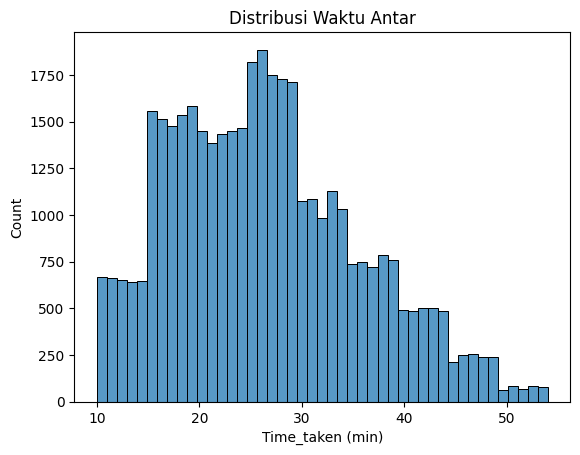

In [51]:
sns.histplot(df["Time_taken (min)"], bins=45)
plt.title("Distribusi Waktu Antar")
plt.show()

In [52]:
df[["Time_taken (min)", "distance_km", "Delivery_person_Age",
    "Delivery_person_Ratings", "multiple_deliveries"]].describe().round(2)

,Time_taken (min),distance_km,Delivery_person_Age,Delivery_person_Ratings,multiple_deliveries
count,40100.00,40100.00,40100.00,40100.00,40100.00
mean,26.31,9.71,29.55,4.63,0.73
std,9.37,5.60,5.76,0.31,0.58
min,10.00,1.47,20.00,2.50,0.00
25%,19.00,4.66,25.00,4.50,0.00
50%,26.00,9.19,30.00,4.70,1.00
75%,32.00,13.63,35.00,4.90,1.00
max,54.00,20.97,39.00,5.00,3.00


In [53]:
df["distance_group"] = pd.cut(df["distance_km"], bins=[0, 5, 10, 15, 25],
                              labels=["0-5 km", "5-10 km", "10-15 km", "15-21 km"])

In [54]:
df["late_threshold"] = (df.groupby("distance_group", observed=True)["Time_taken (min)"]
                          .transform(lambda s: s.quantile(0.75)))

In [55]:
df["is_late"] = df["Time_taken (min)"] > df["late_threshold"]

In [56]:
df.groupby("distance_group", observed=True).agg(
    jumlah=("Time_taken (min)", "size"),
    rata2=("Time_taken (min)", "mean"),
    batas=("late_threshold", "first"),
    persen_telat=("is_late", "mean")).round(2)

,jumlah,rata2,batas,persen_telat
distance_group,,,,
0-5 km,10799,22.20,27.0,0.24
5-10 km,10822,24.37,29.0,0.24
10-15 km,10805,29.84,38.0,0.22
15-21 km,7674,29.86,38.0,0.22


In [57]:
df["distance_group"] = pd.cut(df["distance_km"], bins=[0, 5, 10, 25],
                              labels=["0-5 km", "5-10 km", ">10 km"])
df["late_threshold"] = (df.groupby("distance_group", observed=True)["Time_taken (min)"]
                          .transform(lambda s: s.quantile(0.75)))
df["is_late"] = df["Time_taken (min)"] > df["late_threshold"]

In [58]:
faktor = ["Road_traffic_density", "Weather_conditions", "Vehicle_condition",
          "Type_of_vehicle", "multiple_deliveries", "Festival", "City", "Type_of_order"]

for f in faktor:
    hasil = (df.groupby(f)
               .agg(jumlah=("is_late", "size"),
                    rata2=("Time_taken (min)", "mean"),
                    persen_telat=("is_late", "mean"))
               .round(2)
               .sort_values("persen_telat", ascending=False))
    print(f"\n=== {f} ===")
    print(hasil)


=== Road_traffic_density ===
                      jumlah  rata2  persen_telat
Road_traffic_density                             
High                    3947  27.19          0.43
Jam                    12643  31.15          0.37
Medium                  9772  26.75          0.18
Low                    13738  21.30          0.07

=== Weather_conditions ===
                    jumlah  rata2  persen_telat
Weather_conditions                             
Fog                   6804  29.00          0.32
Cloudy                6690  28.93          0.31
Sandstorms            6675  25.89          0.23
Stormy                6771  25.89          0.23
Windy                 6638  26.12          0.23
Sunny                 6522  21.89          0.07

=== Vehicle_condition ===
                   jumlah  rata2  persen_telat
Vehicle_condition                             
0                   13369  30.07          0.35
1                   13378  24.37          0.17
2                   13353  24.49          0

In [59]:
semi = df[df["City"] == "Semi-Urban"]
print(semi["Time_taken (min)"].describe())
for c in ["Road_traffic_density", "Vehicle_condition", "Festival", "multiple_deliveries"]:
    print(c, semi[c].value_counts().to_dict())

count    138.000000
mean      49.673913
std        2.774132
min       44.000000
25%       48.000000
50%       49.000000
75%       52.750000
max       54.000000
Name: Time_taken (min), dtype: float64
Road_traffic_density {'Jam': 114, 'High': 14, 'Medium': 10}
Vehicle_condition {0: 120, 1: 9, 2: 9}
Festival {'No': 103, 'Yes': 35}
multiple_deliveries {1.0: 65, 3.0: 34, 2.0: 20, 0.0: 19}


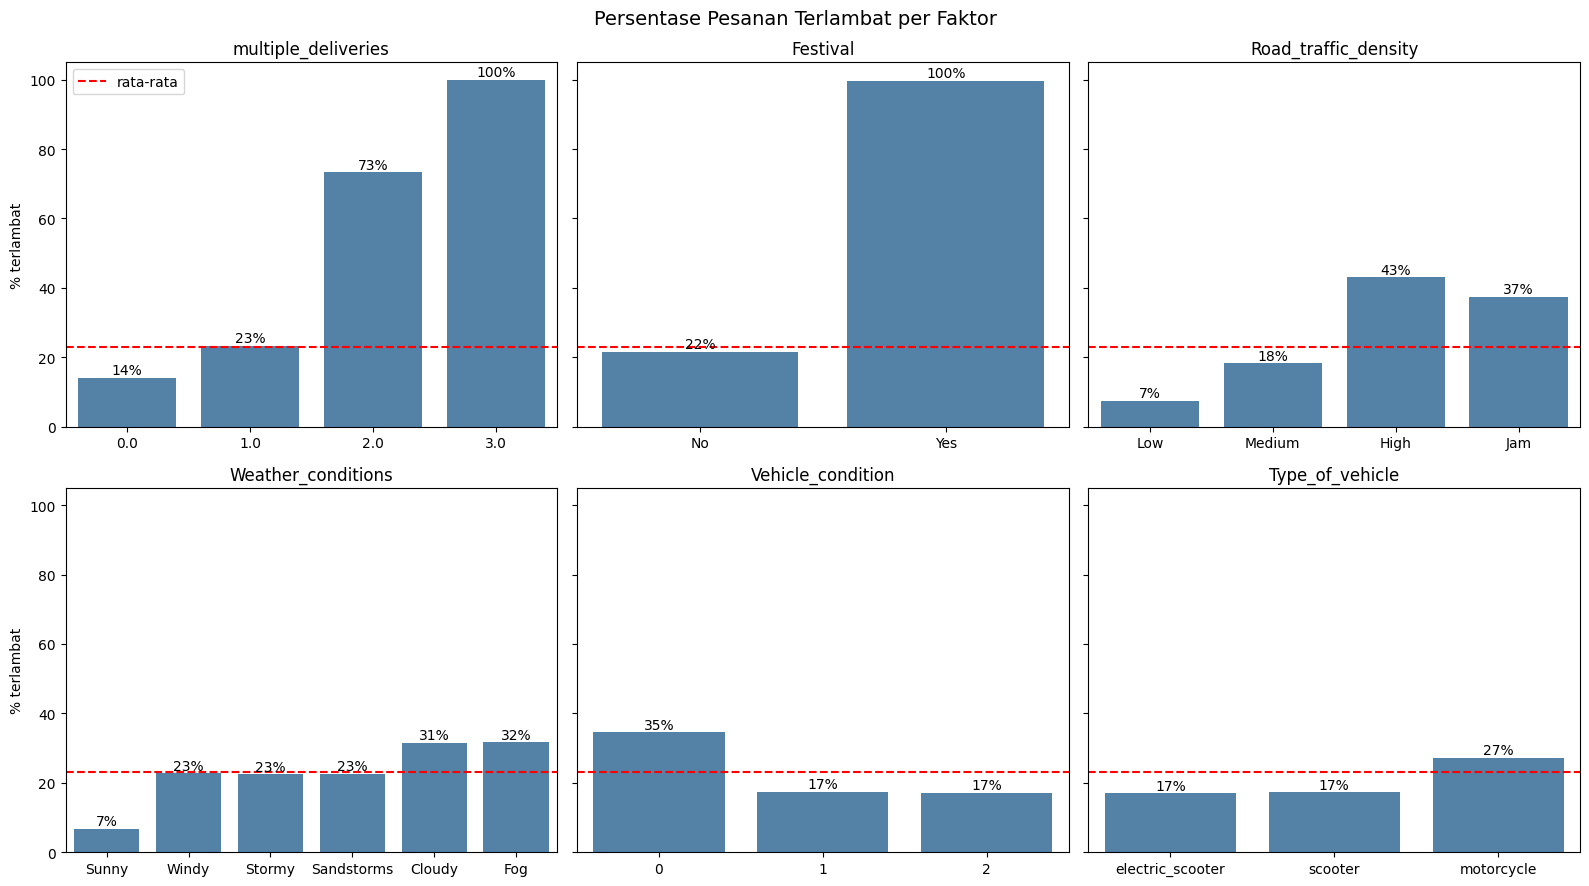

In [60]:
urutan = {
    "multiple_deliveries": [0.0, 1.0, 2.0, 3.0],
    "Festival": ["No", "Yes"],
    "Road_traffic_density": ["Low", "Medium", "High", "Jam"],
    "Weather_conditions": ["Sunny", "Windy", "Stormy", "Sandstorms", "Cloudy", "Fog"],
    "Vehicle_condition": [0, 1, 2],
    "Type_of_vehicle": ["electric_scooter", "scooter", "motorcycle"],
}

rata2_telat = df["is_late"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
for ax, (kolom, kategori) in zip(axes.flat, urutan.items()):
    persen = df[df[kolom].isin(kategori)].groupby(kolom)["is_late"].mean().reindex(kategori) * 100
    sns.barplot(x=persen.index.astype(str), y=persen.values, ax=ax, color="steelblue")
    ax.axhline(rata2_telat, color="red", linestyle="--", label="rata-rata")
    ax.set_title(kolom)
    ax.set_xlabel("")
    ax.set_ylabel("% terlambat")
    for i, v in enumerate(persen.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center")

axes[0, 0].legend()
plt.suptitle("Persentase Pesanan Terlambat per Faktor", fontsize=14)
plt.tight_layout()
plt.show()

### Insight: Persentase Pesanan Terlambat per Faktor

**1. Multiple_deliveries**
- **Temuan:** kurir yang membawa 2 pesanan tambahan terlambat 73%, dan yang membawa 3 pesanan tambahan terlambat 100%. Bandingkan dengan kurir tanpa pesanan tambahan yang hanya terlambat 14%.
- **Artinya:** semakin banyak pesanan yang dibawa sekaligus, risiko terlambat naik semakin tajam, terutama setelah lebih dari 1 pesanan tambahan.
- **Catatan:** jumlah kurir yang membawa 3 pesanan tambahan hanya 309 pesanan, jadi angka 100% perlu dilihat dengan hati-hati.

**2. Festival**
- **Temuan:** pengiriman pada saat festival 100% terlambat, sedangkan saat tidak ada festival 22%.
- **Artinya:** saat festival, pesanan meningkat dan jalanan lebih ramai, sehingga kurir tidak bisa mengantar tepat waktu.
- **Catatan:** pengiriman saat festival hanya 783 pesanan (sekitar 2% data), jadi sampelnya kecil.

**3. Road_traffic_density**
- **Temuan:** traffic high (padat) terlambat 43% dan jam (macet) 37%, jauh di atas traffic low (lancar) yang hanya 7%.
- **Artinya:** kondisi lalu lintas padat dan macet memiliki efek keterlambatan yang tidak jauh berbeda.
- **Catatan:** high terlihat lebih tinggi karena pesanannya jarak dekat (rata-rata 4,4 km), sedangkan jam kebanyakan jarak jauh (rata-rata 12 km). Jika dibandingkan pada jarak yang sama, keduanya hampir sama (0–5 km: 49% vs 49%).

**4. Weather_conditions**
- **Temuan:** cuaca cloudy (31%) dan fog (32%) paling sering menyebabkan terlambat, sedangkan cuaca sunny hanya 7%.
- **Artinya:** pada cuaca berawan dan berkabut, kurir lebih sering mengalami keterlambatan daripada saat cuaca cerah.
- **Catatan:** cuaca tidak bisa dikendalikan, tetapi bisa diprediksi lewat ramalan cuaca.

**5. Vehicle_condition**
- **Temuan:** kendaraan kondisi 0 terlambat 35%, sedangkan kondisi 1 dan 2 hanya 17%.
- **Artinya:** kendaraan dengan kondisi paling buruk membuat pengiriman lebih lambat. Semua 231 pesanan paling lama (lebih dari 51 menit) memakai kendaraan kondisi 0.
- **Catatan:** kondisi 1 dan 2 hasilnya sama, jadi masalahnya ada di kendaraan kondisi 0 saja.

**6. Type_of_vehicle**
- **Temuan:** motorcycle lebih sering terlambat (27%) dibanding scooter dan electric scooter (17%).
- **Artinya:** motorcycle terlambat bukan karena jenis kendaraannya, tetapi karena semua kendaraan kondisi 0 adalah motorcycle.
- **Catatan:** kondisi lalu lintas untuk ketiga jenis kendaraan sama, jadi motorcycle tidak lebih sering terjebak macet. Faktor 5 dan 6 sebenarnya satu temuan yang sama.

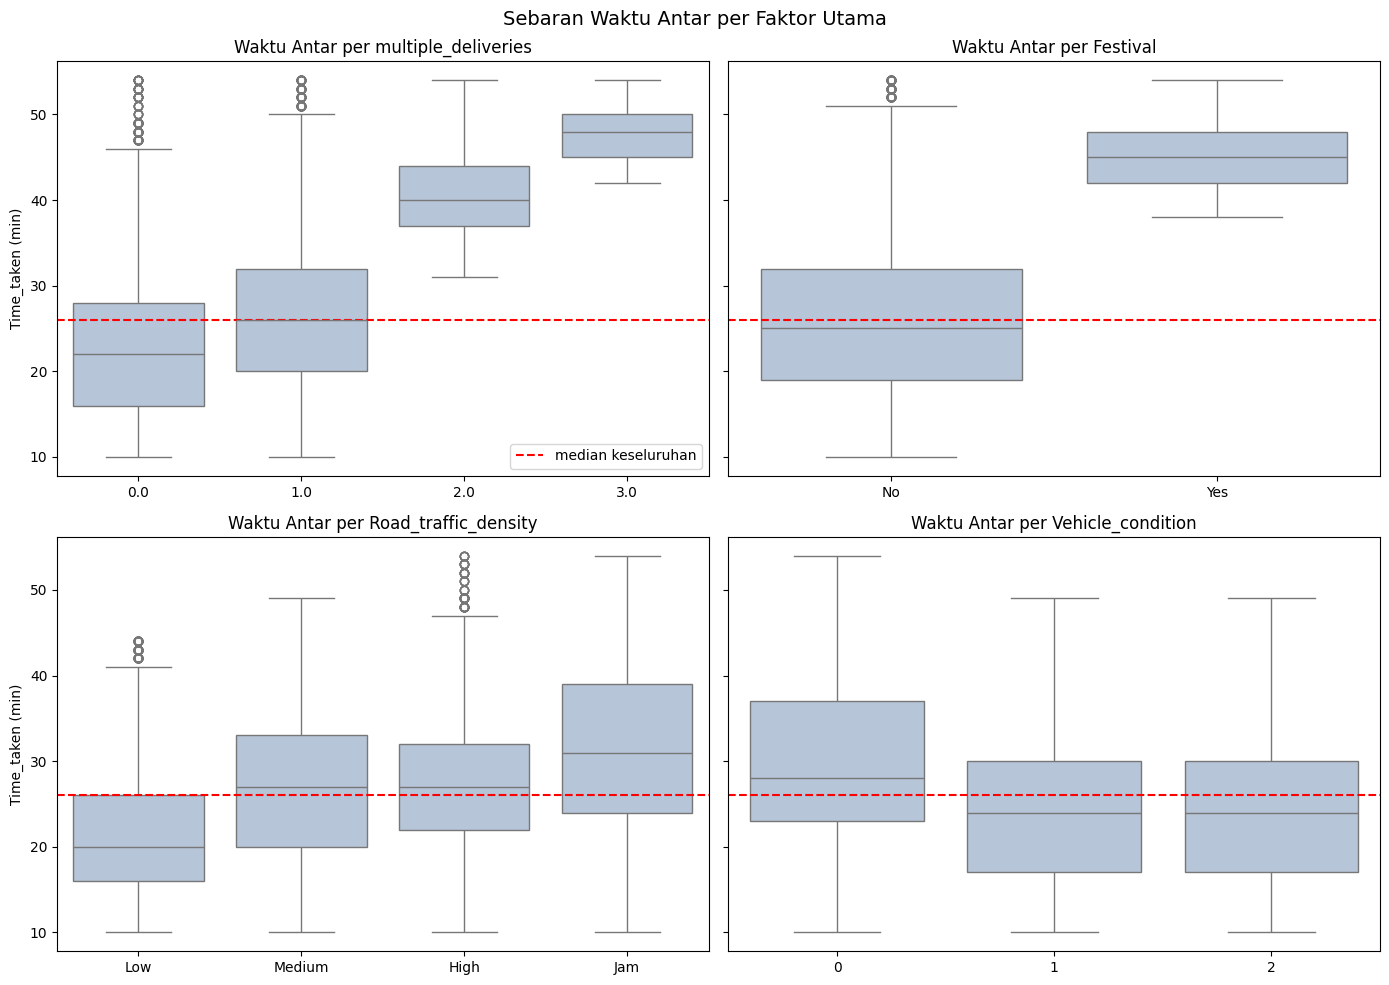

In [61]:
urutan_box = {
    "multiple_deliveries": [0.0, 1.0, 2.0, 3.0],
    "Festival": ["No", "Yes"],
    "Road_traffic_density": ["Low", "Medium", "High", "Jam"],
    "Vehicle_condition": [0, 1, 2],
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
for ax, (kolom, kategori) in zip(axes.flat, urutan_box.items()):
    data = df[df[kolom].isin(kategori)]
    sns.boxplot(data=data, x=kolom, y="Time_taken (min)", order=kategori,
                ax=ax, color="lightsteelblue")
    ax.axhline(df["Time_taken (min)"].median(), color="red", linestyle="--",
               label="median keseluruhan")
    ax.set_title(f"Waktu Antar per {kolom}")
    ax.set_xlabel("")

axes[0, 0].legend()
plt.suptitle("Sebaran Waktu Antar per Faktor Utama", fontsize=14)
plt.tight_layout()
plt.show()

### Insight: Sebaran Waktu Antar per Faktor

**1. Festival dan multiple_deliveries membuat seluruh sebaran waktu antar bergeser ke atas**
- **Temuan:** Saat festival, pengiriman paling cepat butuh 38 menit (median 45 menit), padahal saat tidak ada festival median hanya 25 menit dan 75% pesanan selesai di bawah 32 menit. Pola yang sama terjadi pada multiple_deliveries: kurir dengan 2 pesanan tambahan paling cepat 31 menit (median 40), dan dengan 3 pesanan tambahan paling cepat 42 menit (median 48), sedangkan tanpa pesanan tambahan median hanya 22 menit.
- **Artinya:** Pada kondisi ini, bahkan pengiriman yang paling lancar pun tetap lambat. Keterlambatannya bukan karena sebagian kecil pesanan yang bermasalah, tetapi karena kondisi tersebut memperlambat semua pesanan.

**2. Road_traffic_density dan Vehicle_condition menaikkan risiko terlambat, tetapi tidak membuat semua pesanan lambat**
- **Temuan:** Saat lalu lintas macet (Jam), median waktu antar 31 menit, jauh lebih lama dibanding saat lalu lintas rendah (Low) yang hanya 20 menit. Kondisi kendaraan juga menunjukkan pola serupa: kendaraan kondisi 0 memiliki median 28 menit, sedangkan kondisi 1 dan 2 hanya 24 menit. Namun, pengiriman paling cepat di semua kelompok tetap 10 menit, dan kotak boxplot-nya saling tumpang tindih.
- **Artinya:** Berbeda dengan festival dan multiple_deliveries, kondisi ini tidak memperlambat semua pesanan. Masih ada pesanan yang bisa diantar cepat meskipun lalu lintas macet atau kendaraan dalam kondisi buruk. Faktor ini menaikkan peluang terlambat, bukan menjamin terlambat.

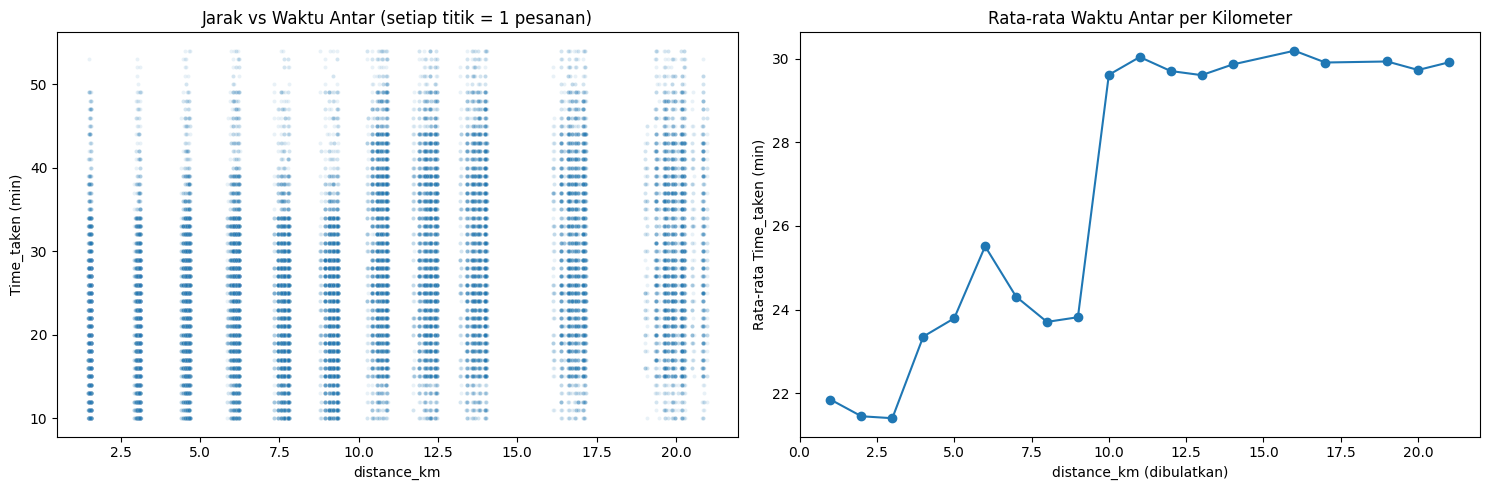

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=df, x="distance_km", y="Time_taken (min)", alpha=0.1, s=8, ax=axes[0])
axes[0].set_title("Jarak vs Waktu Antar (setiap titik = 1 pesanan)")

df["distance_bin"] = df["distance_km"].round()
rata = df.groupby("distance_bin")["Time_taken (min)"].mean()
axes[1].plot(rata.index, rata.values, marker="o")
axes[1].set_title("Rata-rata Waktu Antar per Kilometer")
axes[1].set_xlabel("distance_km (dibulatkan)")
axes[1].set_ylabel("Rata-rata Time_taken (min)")

plt.tight_layout()
plt.show()

### Insight: Jarak vs Waktu Antar

**Waktu antar melonjak di batas 10 km, lalu tidak bertambah lagi**
- **Temuan:** jarak 1-9 km rata-rata pengiriman 21-25 menit, sedangkan jarak di atas 10 km rata-rata 30 menit. Setelah 10 km, waktu pengiriman tidak bertambah lagi (11 km dan 21 km sama-sama sekitar 30 menit).
- **Artinya:** pesanan di atas 10 km sekitar 5-9 menit lebih lama daripada pesanan di bawah 10 km. Namun, di setiap jarak waktu pengiriman tetap bervariasi dari 10 sampai 50 menit (korelasi 0,32), sehingga jarak bukan satu-satunya penyebab keterlambatan.

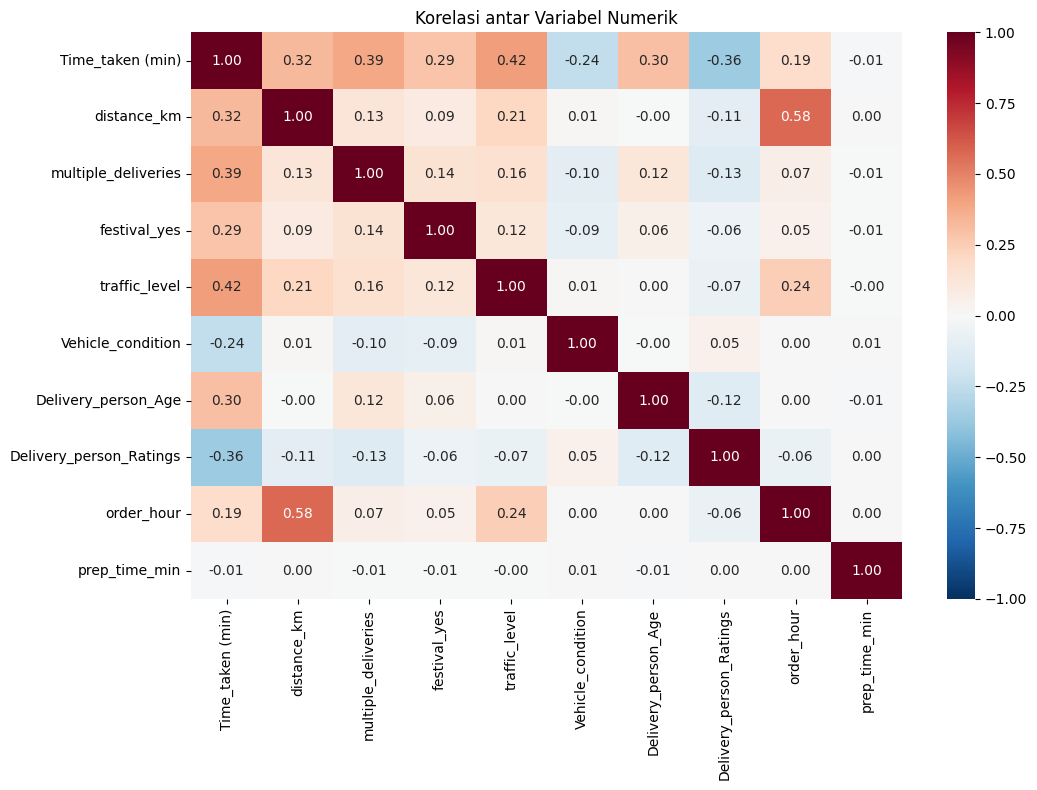

In [63]:
df["festival_yes"] = (df["Festival"] == "Yes").astype(int)
df["traffic_level"] = df["Road_traffic_density"].map({"Low": 0, "Medium": 1, "High": 2, "Jam": 3})

kolom_num = ["Time_taken (min)", "distance_km", "multiple_deliveries", "festival_yes",
             "traffic_level", "Vehicle_condition", "Delivery_person_Age",
             "Delivery_person_Ratings", "order_hour", "prep_time_min"]

plt.figure(figsize=(11, 8))
sns.heatmap(df[kolom_num].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Korelasi antar Variabel Numerik")
plt.tight_layout()
plt.show()

### Insight: Korelasi antar Variabel

**1. Faktor traffic_level, multiple_deliveries, distance_km, dan festival memiliki hubungan positif sedang dengan time_taken**
- **Temuan:** traffic_level memiliki korelasi 0,42, multiple_deliveries 0,39, distance_km 0,32, dan festival (yes) 0,29.
- **Artinya:** jika faktor-faktor ini naik, waktu pengiriman cenderung bertambah. Namun tidak ada satu faktor yang sangat dominan, sehingga keterlambatan paling parah terjadi ketika beberapa faktor muncul bersamaan.

**2. Faktor dari sisi kurir: delivery_person_age dan delivery_person_ratings**
- **Temuan:** delivery_person_age memiliki korelasi 0,30 (usia 20-30 tahun rata-rata 23-24 menit, usia 31-39 tahun sekitar 29,5 menit) dan delivery_person_ratings memiliki korelasi -0,36 (rating ≤4,0 rata-rata 36 menit, rating ≥4,6 sekitar 24,5 menit).
- **Artinya:** kurir yang lebih tua cenderung mengantar lebih lambat, dan kurir dengan rating tinggi cenderung mengantar lebih cepat. Namun rating diberikan pelanggan setelah pengiriman, jadi bisa saja pengiriman cepat yang membuat rating tinggi, bukan sebaliknya. Usia juga tidak bisa dijadikan dasar keputusan karena berisiko diskriminatif.

**3. Faktor prep_time tidak mempengaruhi waktu pengiriman**
- **Temuan:** prep_time memiliki korelasi -0,01 dengan waktu pengiriman.
- **Artinya:** tidak ada hubungan antara waktu persiapan restoran dengan waktu pengiriman, sehingga perbaikan sebaiknya difokuskan pada sisi kurir dan pengantaran, bukan restoran.

In [64]:
df.to_csv("zomato_clean.csv", index=False)